In [4]:
import pandas as pd

df = pd.read_csv(r"E:\Research WORK\7. ML green hydrogen microgrid\ALL RESULT 7 DAY WITH BESS.csv")

print(df.info())
print(df.head())
print(df.isnull().sum())
print(df.columns)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60481 entries, 0 to 60480
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   time                      60481 non-null  int64  
 1   PElectrolyzer             60481 non-null  float64
 2   PSolar                    60481 non-null  float64
 3   PStorage                  60481 non-null  float64
 4   ELECTROLYZER CURRENT      60481 non-null  float64
 5   STORAGE CURRENT           60481 non-null  float64
 6   SOLAR CURRENT             60481 non-null  float64
 7   battery VOLTAGE           60481 non-null  float64
 8   grid volt                 60481 non-null  float64
 9   ELECTROLYZER ENERGY       60481 non-null  float64
 10  SOLAR ENERGY              60481 non-null  float64
 11  STORAGE ENERGY            60481 non-null  float64
 12  SOC                       60481 non-null  float64
 13  Mh2(hydrogen production)  60481 non-null  float64
dtypes: flo

Dataset columns:
['time', 'PElectrolyzer', 'PSolar', 'PStorage', 'ELECTROLYZER CURRENT', 'STORAGE CURRENT', 'SOLAR CURRENT', 'battery VOLTAGE', 'grid volt', 'ELECTROLYZER ENERGY', 'SOLAR ENERGY', 'STORAGE ENERGY', 'SOC', 'Mh2(hydrogen production)', 'mh2_lag1', 'hour_sin', 'hour_cos']

Using target column: Mh2(hydrogen production)

Features used:
['time', 'PElectrolyzer', 'PSolar', 'PStorage', 'ELECTROLYZER CURRENT', 'STORAGE CURRENT', 'SOLAR CURRENT', 'battery VOLTAGE', 'grid volt', 'ELECTROLYZER ENERGY', 'SOLAR ENERGY', 'STORAGE ENERGY', 'SOC', 'mh2_lag1', 'hour_sin', 'hour_cos', 'electrolyzer_eff', 'solar_storage_ratio']

Features shape: (60481, 18)
Target shape: (60481,)

Random Forest Performance
MAE  : 18.4280
MSE  : 385.7271
RMSE : 19.6399
R²   : -5.9634

Sequence train shape: (51832, 10, 18) (51832,)
Sequence test shape: (8639, 10, 18) (8639,)
Actual test shape: (8639,)

Epoch 1/30
810/810 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 3.2752e-04 - mae: 0.0061 - val_loss: 2.6987e-04 -

,Model,MAE,MSE,RMSE,R^2,Best Use Case
0,Random Forest,18.4280,385.7271,19.6399,-5.9634,Static baseline
1,LSTM,3.5077,15.7104,3.9636,0.7161,Accurate time-series forecasting
2,GRU,4.0953,21.6828,4.6565,0.6082,Lightweight sequence forecasting
3,Transformer Encoder,0.1306,0.0235,0.1532,0.9996,Long-range temporal dependency modeling


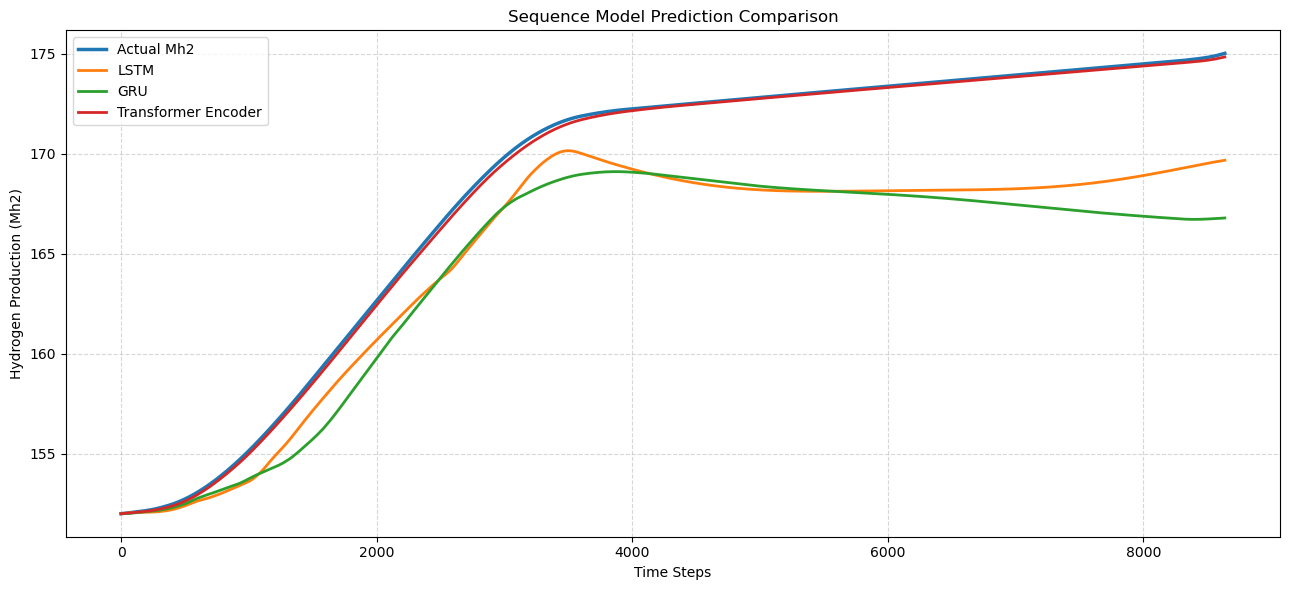

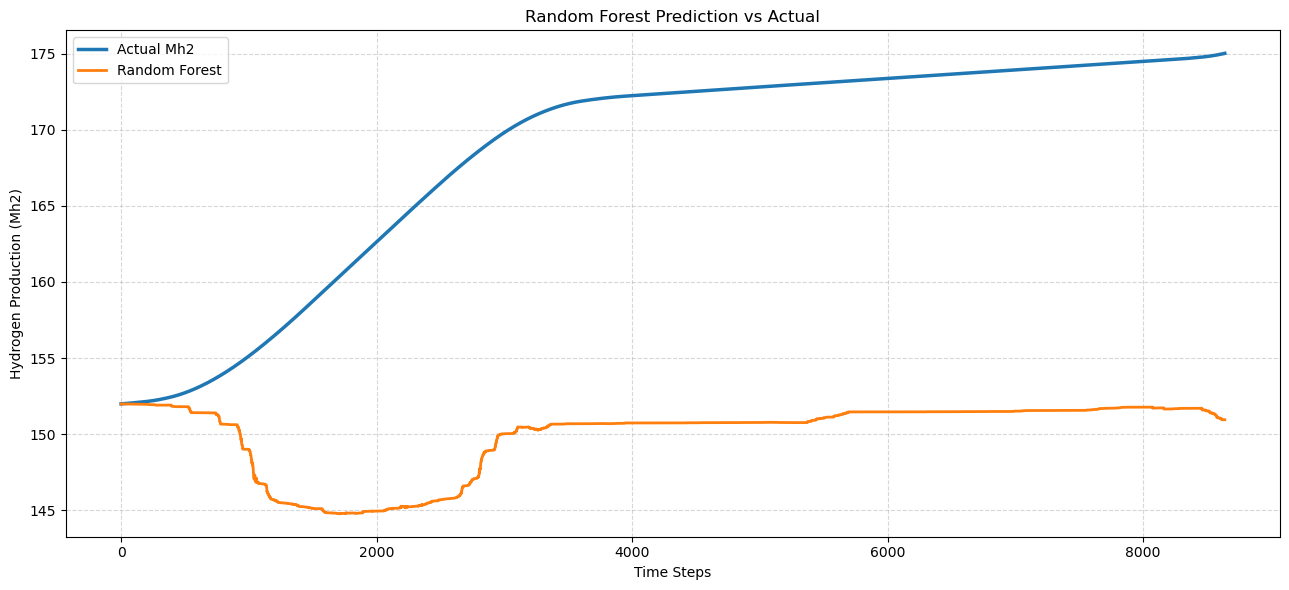

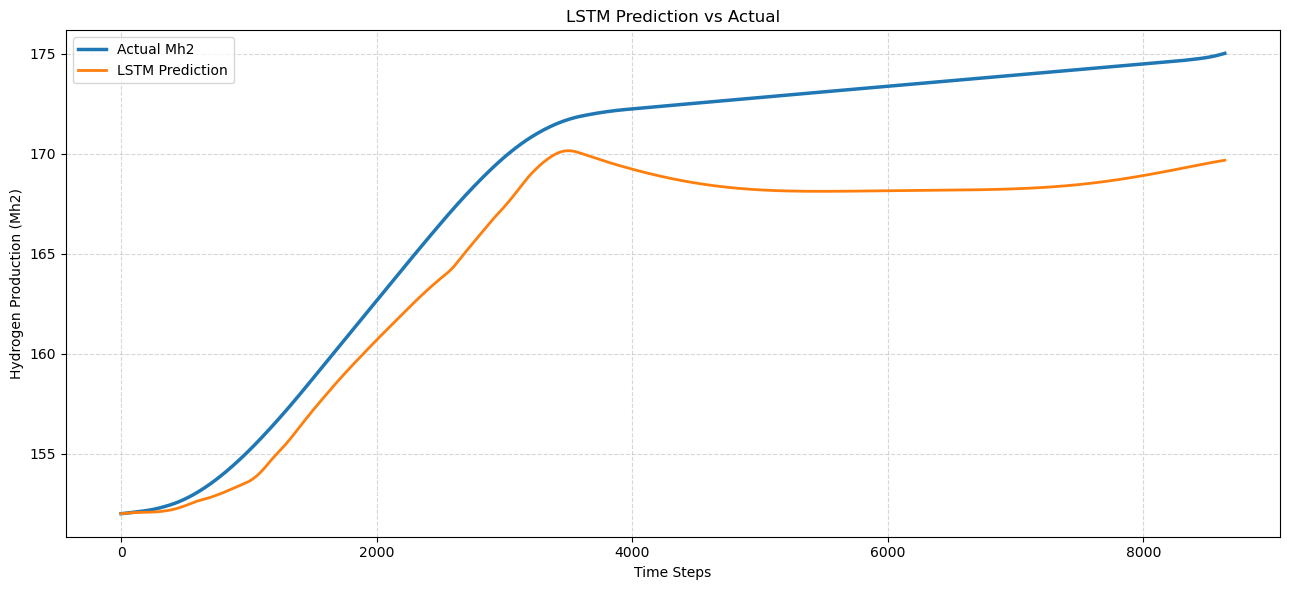

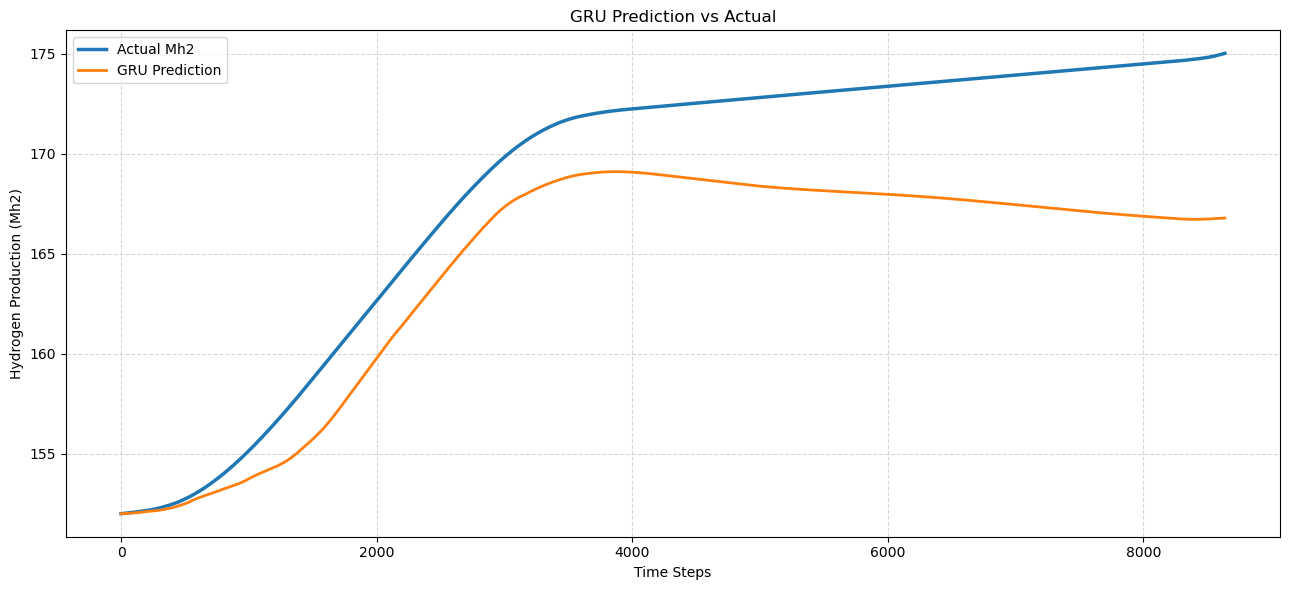

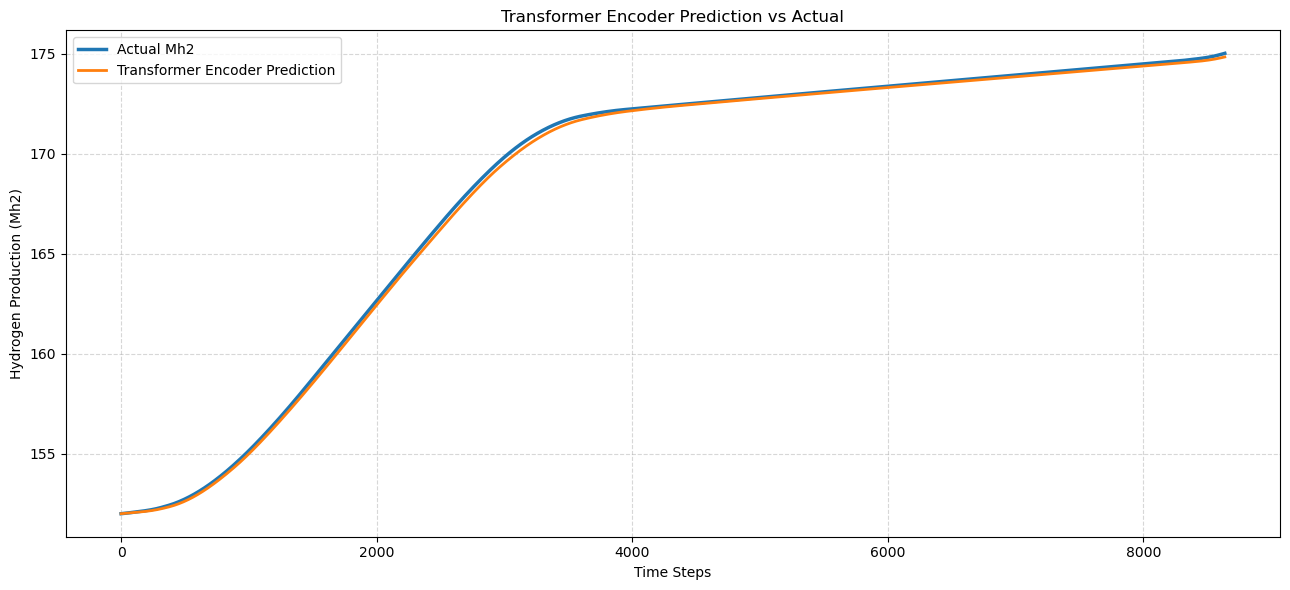


All corrected results and figures saved in:
E:\Research WORK\7. ML green hydrogen microgrid\FIGURES


In [6]:
# ============================================================
# CELL 2: Corrected RF vs LSTM vs GRU vs Transformer Comparison
# Separate EarlyStopping for each deep learning model
# ============================================================

import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Input, Dense, LSTM, GRU, MultiHeadAttention,
    LayerNormalization, Dropout, GlobalAveragePooling1D
)
from tensorflow.keras.callbacks import EarlyStopping

# ============================================================
# 1. Reproducibility
# ============================================================
np.random.seed(42)
tf.random.set_seed(42)

# ============================================================
# 2. Save folder
# ============================================================
save_folder = r"E:\Research WORK\7. ML green hydrogen microgrid\FIGURES"
os.makedirs(save_folder, exist_ok=True)

# ============================================================
# 3. Clean column names
# ============================================================
df.columns = df.columns.str.strip()

print("Dataset columns:")
print(df.columns.tolist())

# ============================================================
# 4. Select target column
# ============================================================
target_col = "Mh2(hydrogen production)"

if target_col not in df.columns:
    possible_targets = [
        col for col in df.columns
        if "h2" in col.lower() or "hydrogen" in col.lower()
    ]

    if len(possible_targets) == 0:
        raise ValueError("Hydrogen production column not found. Check dataset column names.")
    else:
        target_col = possible_targets[0]

print("\nUsing target column:", target_col)

target = df[target_col].copy()

# ============================================================
# 5. Feature engineering
# ============================================================
df["mh2_lag1"] = target.shift(1).fillna(0)

# Optional engineered features
if "ELECTROLYZER ENERGY" in df.columns and "SOLAR ENERGY" in df.columns:
    df["electrolyzer_eff"] = df["ELECTROLYZER ENERGY"] / (df["SOLAR ENERGY"] + 1e-6)

if "SOLAR ENERGY" in df.columns and "STORAGE ENERGY" in df.columns:
    df["solar_storage_ratio"] = df["SOLAR ENERGY"] / (
        df["SOLAR ENERGY"] + df["STORAGE ENERGY"] + 1e-6
    )

# Time encoding
df["time_index"] = np.arange(len(df))
df["hour_sin"] = np.sin(2 * np.pi * df["time_index"] / 8640)
df["hour_cos"] = np.cos(2 * np.pi * df["time_index"] / 8640)
df = df.drop(columns=["time_index"])

# ============================================================
# 6. Prepare features and target
# ============================================================
features = df.drop(columns=[target_col])
features = features.select_dtypes(include=[np.number])
features = features.fillna(0)

target = df[target_col].fillna(0)

scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

print("\nFeatures used:")
print(features.columns.tolist())

print("\nFeatures shape:", features_scaled.shape)
print("Target shape:", target.shape)

# ============================================================
# 7. Metric function
# ============================================================
def regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return mae, mse, rmse, r2

# ============================================================
# 8. Random Forest Model
# ============================================================
train_size = int(len(features_scaled) * 6 / 7)

X_train = features_scaled[:train_size]
X_test = features_scaled[train_size:]

y_train = target.values[:train_size]
y_test = target.values[train_size:]

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

rf_mae, rf_mse, rf_rmse, rf_r2 = regression_metrics(y_test, rf_pred)

print("\nRandom Forest Performance")
print(f"MAE  : {rf_mae:.4f}")
print(f"MSE  : {rf_mse:.4f}")
print(f"RMSE : {rf_rmse:.4f}")
print(f"R²   : {rf_r2:.4f}")

# ============================================================
# 9. Sequence data preparation
# ============================================================
seq_length = 10
epochs = 30
batch_size = 64

def create_sequences(X, y, seq_length):
    X_seq, y_seq = [], []
    for i in range(len(X) - seq_length):
        X_seq.append(X[i:i + seq_length])
        y_seq.append(y[i + seq_length])
    return np.array(X_seq), np.array(y_seq)

def reconstruct_from_diff(y_pred_diff, target_values, start_index):
    initial_value = target_values[start_index - 1]
    return np.cumsum(y_pred_diff) + initial_value

# Predict difference of hydrogen production
mh2_diff = target.diff().fillna(0).values

X_seq, y_seq = create_sequences(features_scaled, mh2_diff, seq_length)

train_size_seq = int(len(X_seq) * 6 / 7)

X_train_seq = X_seq[:train_size_seq]
y_train_seq = y_seq[:train_size_seq]

X_test_seq = X_seq[train_size_seq:]
y_test_seq = y_seq[train_size_seq:]

test_start_index = train_size_seq + seq_length
mh2_test_actual = target.values[test_start_index:]

print("\nSequence train shape:", X_train_seq.shape, y_train_seq.shape)
print("Sequence test shape:", X_test_seq.shape, y_test_seq.shape)
print("Actual test shape:", mh2_test_actual.shape)

# ============================================================
# 10. LSTM Model
# ============================================================
tf.keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

lstm_model = Sequential([
    Input(shape=(seq_length, X_train_seq.shape[2])),
    LSTM(64),
    Dense(32, activation="relu"),
    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

early_stop_lstm = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

lstm_history = lstm_model.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_test_seq, y_test_seq),
    epochs=epochs,
    batch_size=batch_size,
    callbacks=[early_stop_lstm],
    verbose=1
)

lstm_pred_diff = lstm_model.predict(X_test_seq).flatten()
lstm_pred = reconstruct_from_diff(lstm_pred_diff, target.values, test_start_index)

lstm_mae, lstm_mse, lstm_rmse, lstm_r2 = regression_metrics(
    mh2_test_actual,
    lstm_pred
)

print("\nLSTM Performance")
print(f"MAE  : {lstm_mae:.4f}")
print(f"MSE  : {lstm_mse:.4f}")
print(f"RMSE : {lstm_rmse:.4f}")
print(f"R²   : {lstm_r2:.4f}")

# ============================================================
# 11. GRU Model
# ============================================================
tf.keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

gru_model = Sequential([
    Input(shape=(seq_length, X_train_seq.shape[2])),
    GRU(64),
    Dense(32, activation="relu"),
    Dense(1)
])

gru_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

early_stop_gru = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

gru_history = gru_model.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_test_seq, y_test_seq),
    epochs=epochs,
    batch_size=batch_size,
    callbacks=[early_stop_gru],
    verbose=1
)

gru_pred_diff = gru_model.predict(X_test_seq).flatten()
gru_pred = reconstruct_from_diff(gru_pred_diff, target.values, test_start_index)

gru_mae, gru_mse, gru_rmse, gru_r2 = regression_metrics(
    mh2_test_actual,
    gru_pred
)

print("\nGRU Performance")
print(f"MAE  : {gru_mae:.4f}")
print(f"MSE  : {gru_mse:.4f}")
print(f"RMSE : {gru_rmse:.4f}")
print(f"R²   : {gru_r2:.4f}")

# ============================================================
# 12. Transformer Encoder Model
# ============================================================
tf.keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

def transformer_encoder_block(inputs, num_heads=4, key_dim=32, ff_dim=128, dropout_rate=0.1):
    attention_output = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=key_dim
    )(inputs, inputs)

    attention_output = Dropout(dropout_rate)(attention_output)
    x = LayerNormalization(epsilon=1e-6)(inputs + attention_output)

    ff_output = Dense(ff_dim, activation="relu")(x)
    ff_output = Dense(inputs.shape[-1])(ff_output)
    ff_output = Dropout(dropout_rate)(ff_output)

    x = LayerNormalization(epsilon=1e-6)(x + ff_output)
    return x

input_layer = Input(shape=(seq_length, X_train_seq.shape[2]))

x = Dense(64)(input_layer)
x = transformer_encoder_block(x)
x = transformer_encoder_block(x)

x = GlobalAveragePooling1D()(x)
x = Dense(32, activation="relu")(x)
output_layer = Dense(1)(x)

transformer_model = Model(inputs=input_layer, outputs=output_layer)

transformer_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

early_stop_transformer = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

transformer_history = transformer_model.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_test_seq, y_test_seq),
    epochs=epochs,
    batch_size=batch_size,
    callbacks=[early_stop_transformer],
    verbose=1
)

transformer_pred_diff = transformer_model.predict(X_test_seq).flatten()
transformer_pred = reconstruct_from_diff(
    transformer_pred_diff,
    target.values,
    test_start_index
)

transformer_mae, transformer_mse, transformer_rmse, transformer_r2 = regression_metrics(
    mh2_test_actual,
    transformer_pred
)

print("\nTransformer Encoder Performance")
print(f"MAE  : {transformer_mae:.4f}")
print(f"MSE  : {transformer_mse:.4f}")
print(f"RMSE : {transformer_rmse:.4f}")
print(f"R²   : {transformer_r2:.4f}")

# ============================================================
# 13. Final comparison table
# ============================================================
comparison_table = pd.DataFrame({
    "Model": [
        "Random Forest",
        "LSTM",
        "GRU",
        "Transformer Encoder"
    ],
    "MAE": [
        rf_mae,
        lstm_mae,
        gru_mae,
        transformer_mae
    ],
    "MSE": [
        rf_mse,
        lstm_mse,
        gru_mse,
        transformer_mse
    ],
    "RMSE": [
        rf_rmse,
        lstm_rmse,
        gru_rmse,
        transformer_rmse
    ],
    "R^2": [
        rf_r2,
        lstm_r2,
        gru_r2,
        transformer_r2
    ],
    "Best Use Case": [
        "Static baseline",
        "Accurate time-series forecasting",
        "Lightweight sequence forecasting",
        "Long-range temporal dependency modeling"
    ]
})

comparison_table = comparison_table.round(4)

print("\nFinal Model Comparison Table:")
display(comparison_table)

comparison_table.to_csv(
    os.path.join(save_folder, "RF_LSTM_GRU_Transformer_Comparison_Corrected.csv"),
    index=False
)

comparison_table.to_latex(
    os.path.join(save_folder, "RF_LSTM_GRU_Transformer_Comparison_Corrected.tex"),
    index=False
)

# ============================================================
# 14. Plot sequence model comparison
# ============================================================
plt.figure(figsize=(13, 6))

plt.plot(mh2_test_actual, label="Actual Mh2", linewidth=2.5)
plt.plot(lstm_pred, label="LSTM", linewidth=2.0)
plt.plot(gru_pred, label="GRU", linewidth=2.0)
plt.plot(transformer_pred, label="Transformer Encoder", linewidth=2.0)

plt.title("Sequence Model Prediction Comparison")
plt.xlabel("Time Steps")
plt.ylabel("Hydrogen Production (Mh2)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    os.path.join(save_folder, "Fig_Sequence_Model_Comparison_Corrected.png"),
    dpi=300
)

plt.show()

# ============================================================
# 15. Plot RF prediction separately
# ============================================================
plt.figure(figsize=(13, 6))

plt.plot(y_test, label="Actual Mh2", linewidth=2.5)
plt.plot(rf_pred, label="Random Forest", linewidth=2.0)

plt.title("Random Forest Prediction vs Actual")
plt.xlabel("Time Steps")
plt.ylabel("Hydrogen Production (Mh2)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    os.path.join(save_folder, "Fig_RF_Prediction_Corrected.png"),
    dpi=300
)

plt.show()

# ============================================================
# 16. Individual prediction plots
# ============================================================
def save_individual_plot(actual, predicted, model_name, filename):
    plt.figure(figsize=(13, 6))
    plt.plot(actual, label="Actual Mh2", linewidth=2.5)
    plt.plot(predicted, label=f"{model_name} Prediction", linewidth=2.0)
    plt.title(f"{model_name} Prediction vs Actual")
    plt.xlabel("Time Steps")
    plt.ylabel("Hydrogen Production (Mh2)")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.savefig(os.path.join(save_folder, filename), dpi=300)
    plt.show()

save_individual_plot(mh2_test_actual, lstm_pred, "LSTM", "Fig_LSTM_Prediction_Corrected.png")
save_individual_plot(mh2_test_actual, gru_pred, "GRU", "Fig_GRU_Prediction_Corrected.png")
save_individual_plot(mh2_test_actual, transformer_pred, "Transformer Encoder", "Fig_Transformer_Prediction_Corrected.png")

print("\nAll corrected results and figures saved in:")
print(save_folder)

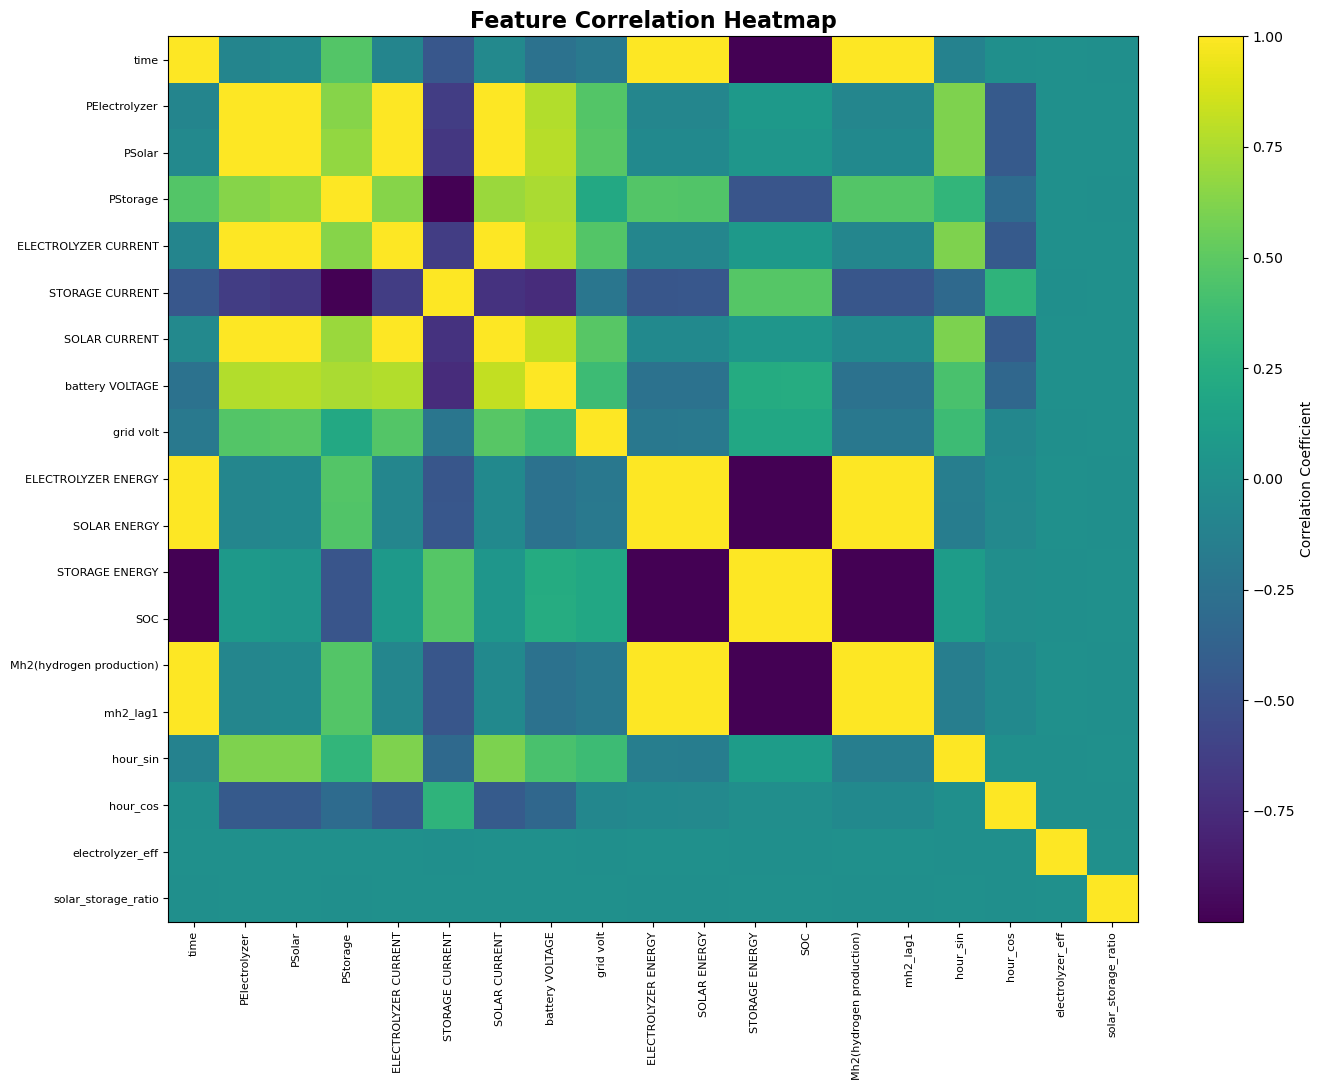

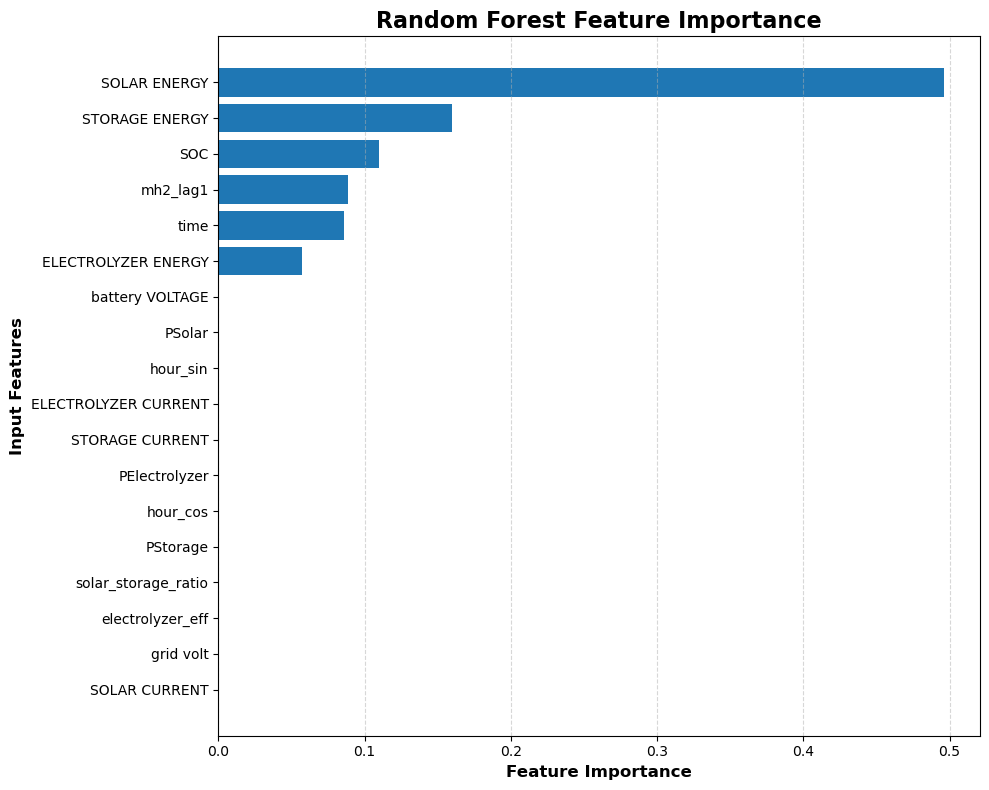

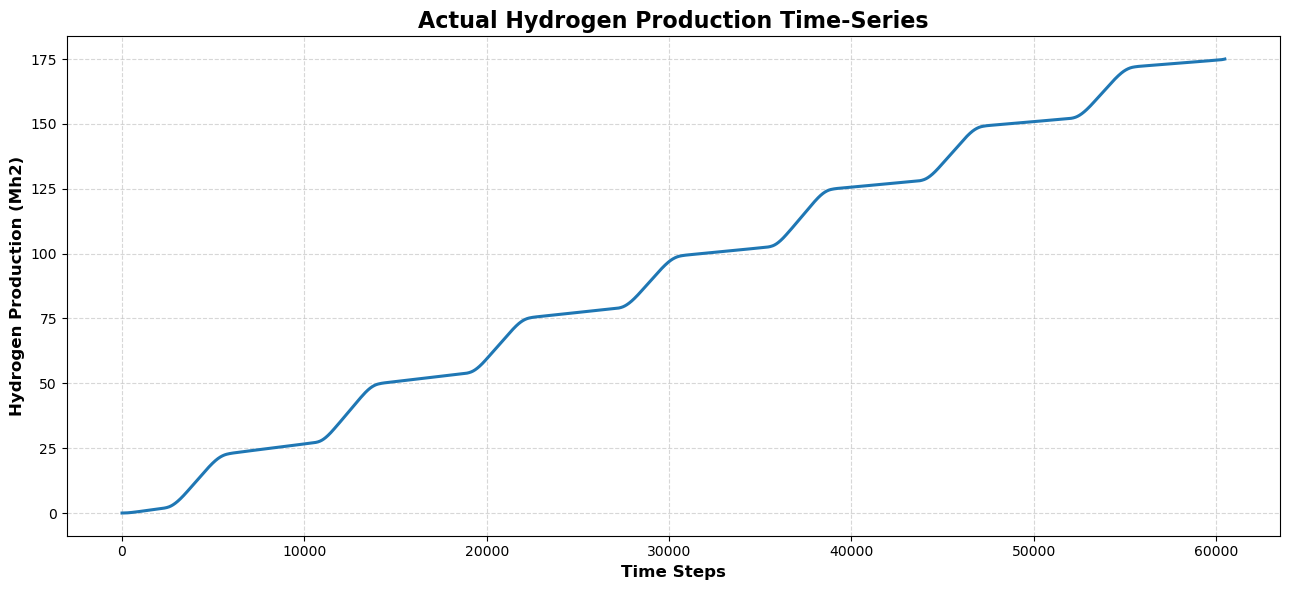

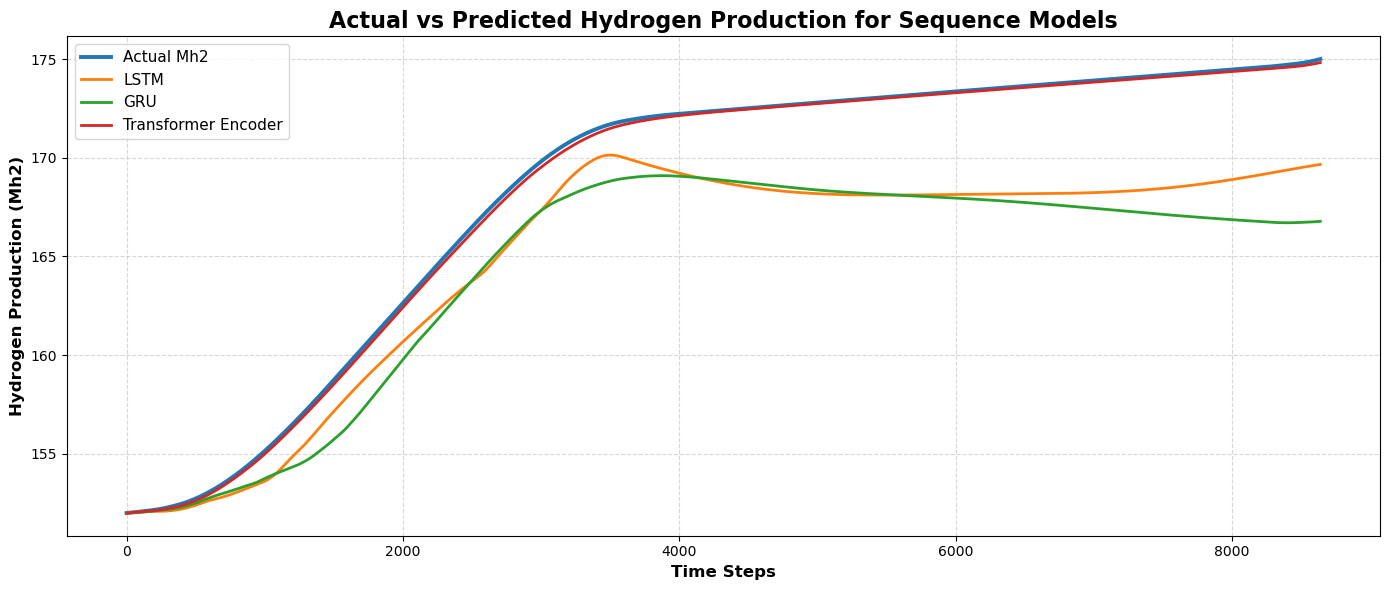

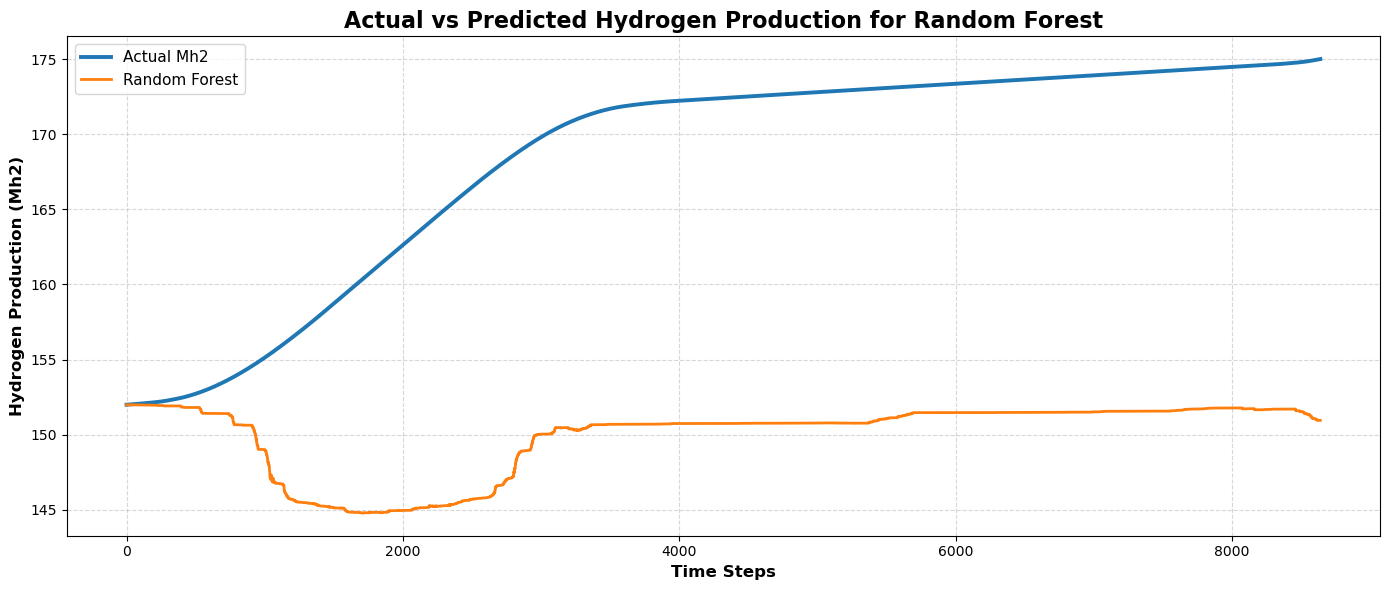

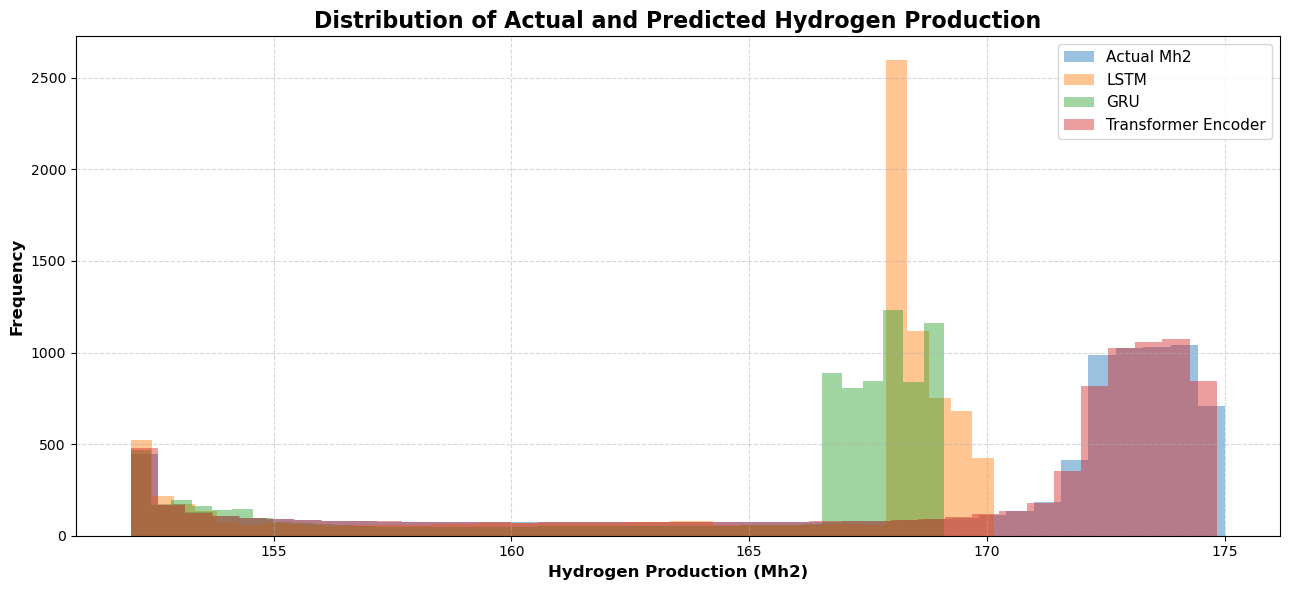

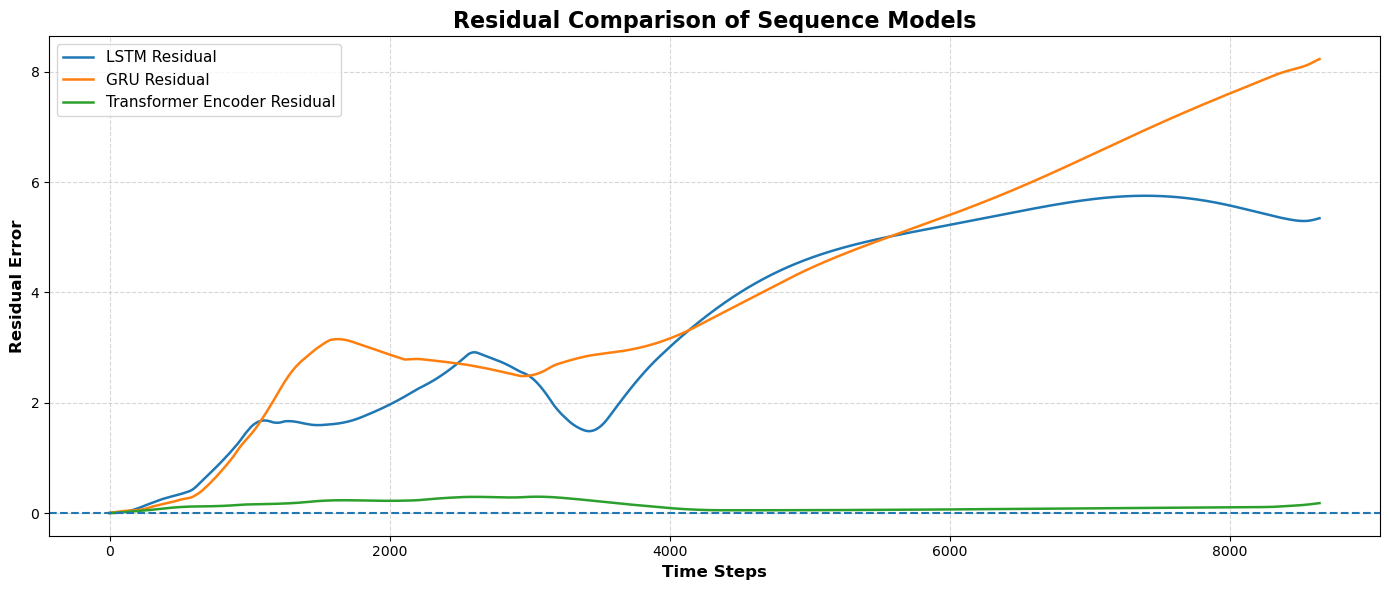

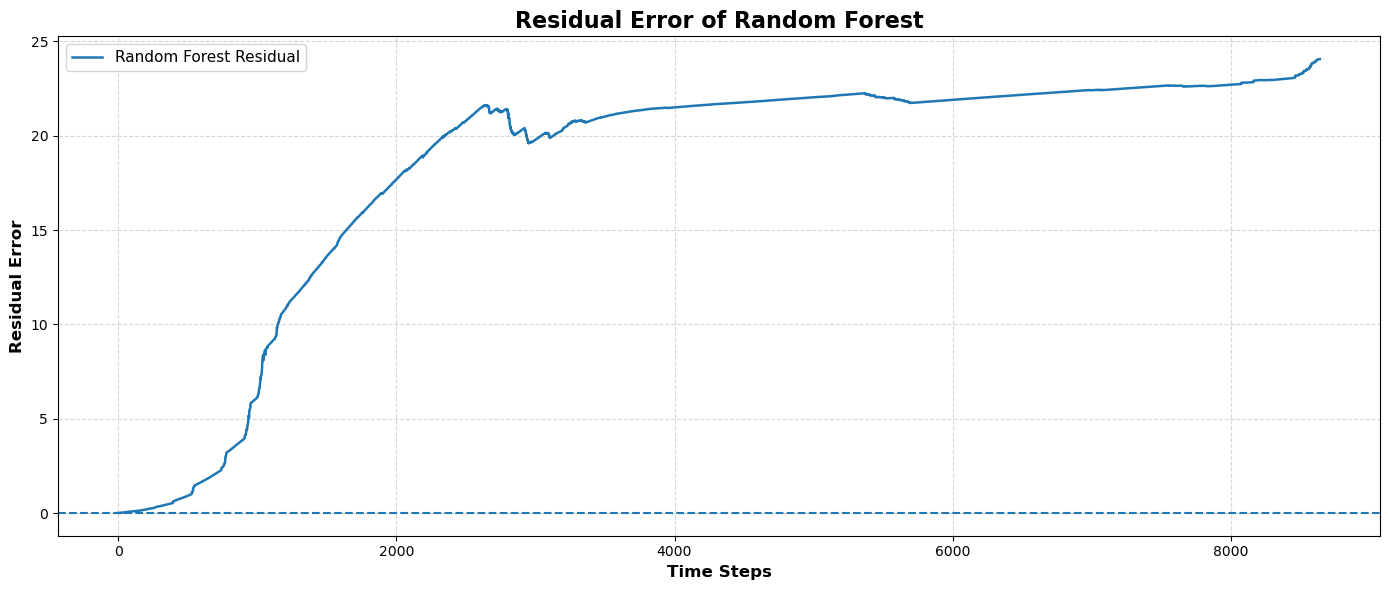

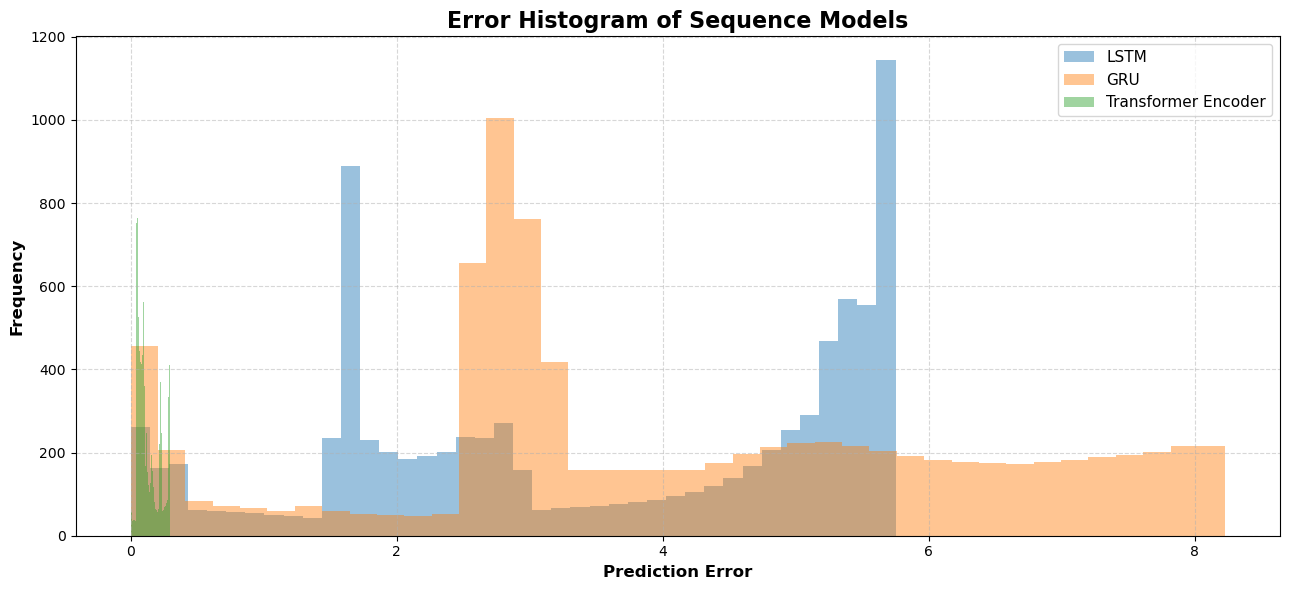

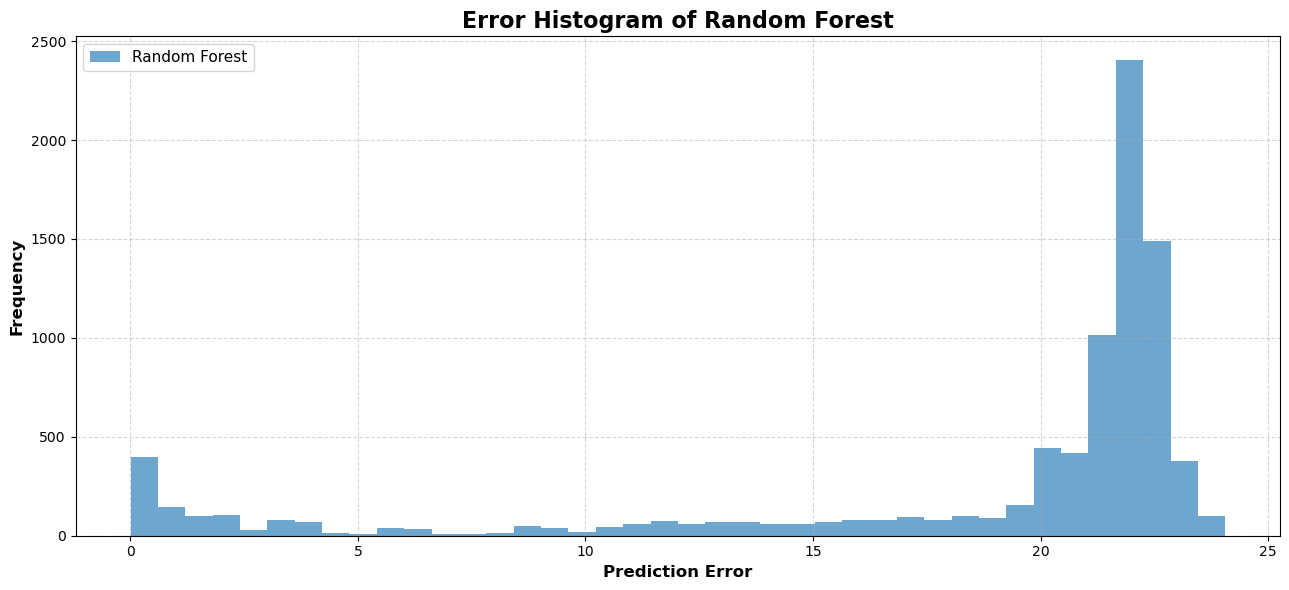

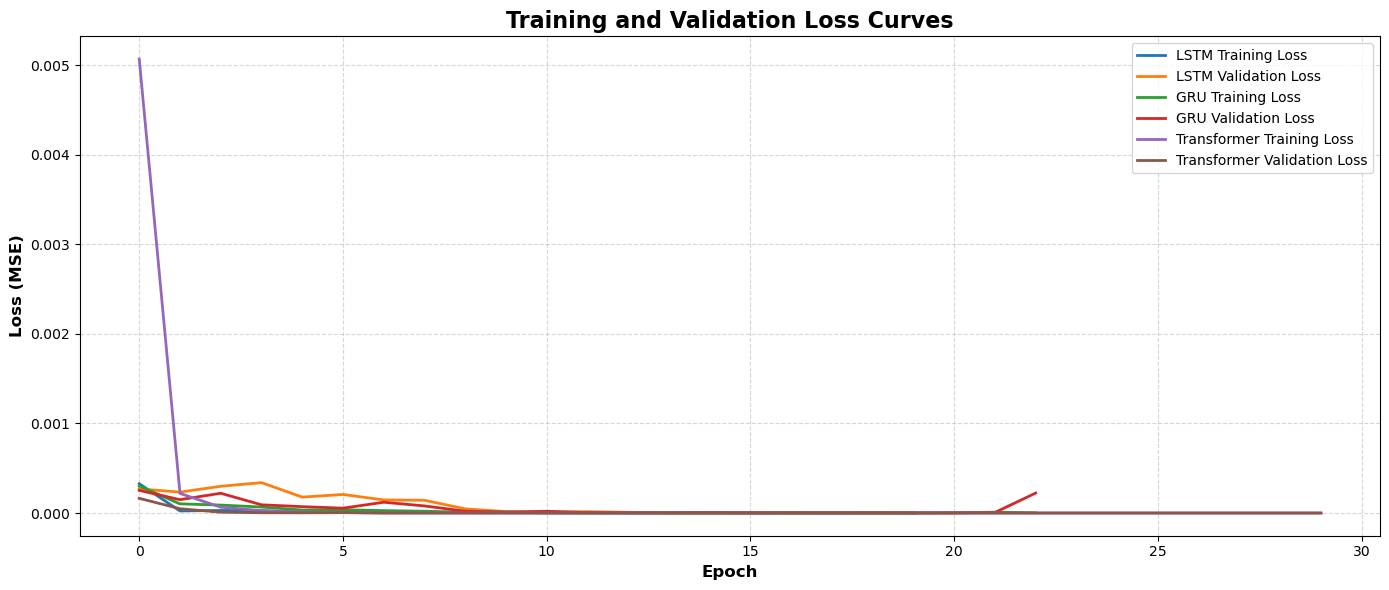

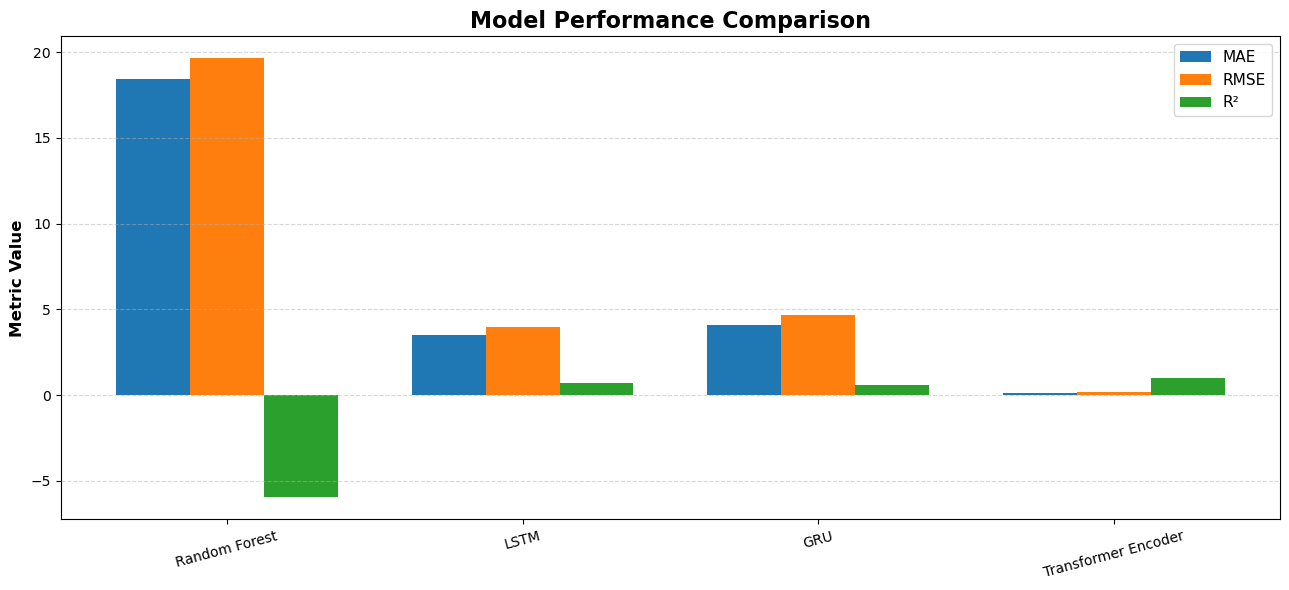

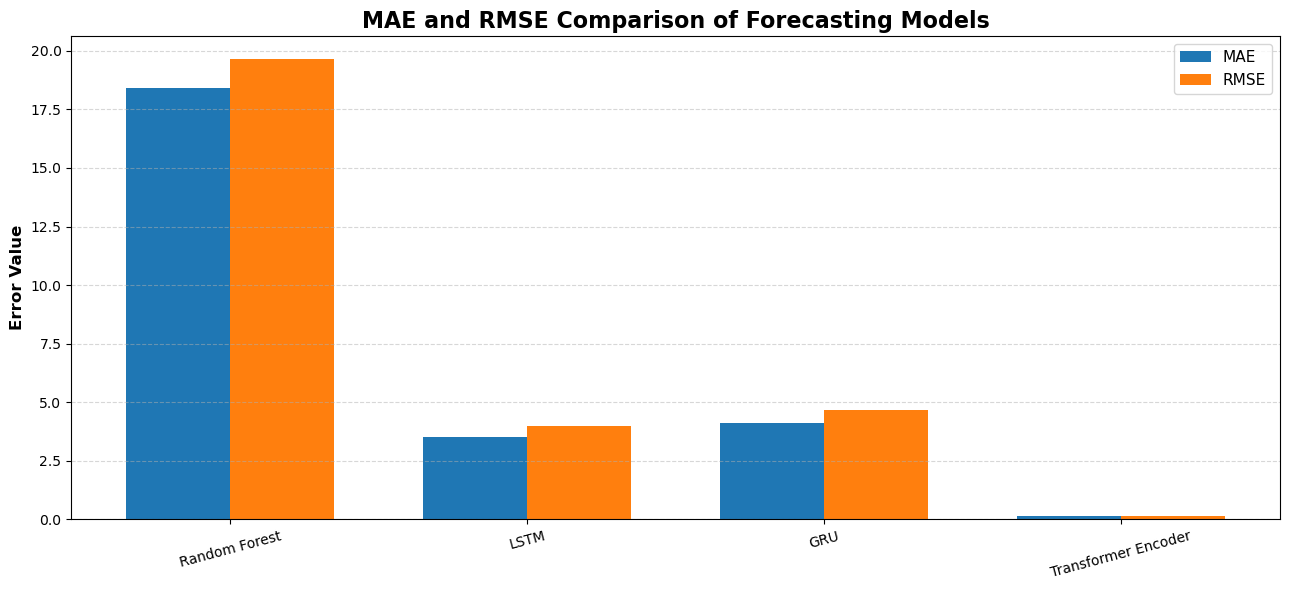

C:\Users\USER\AppData\Local\Temp\ipykernel_12600\3174445662.py:289: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


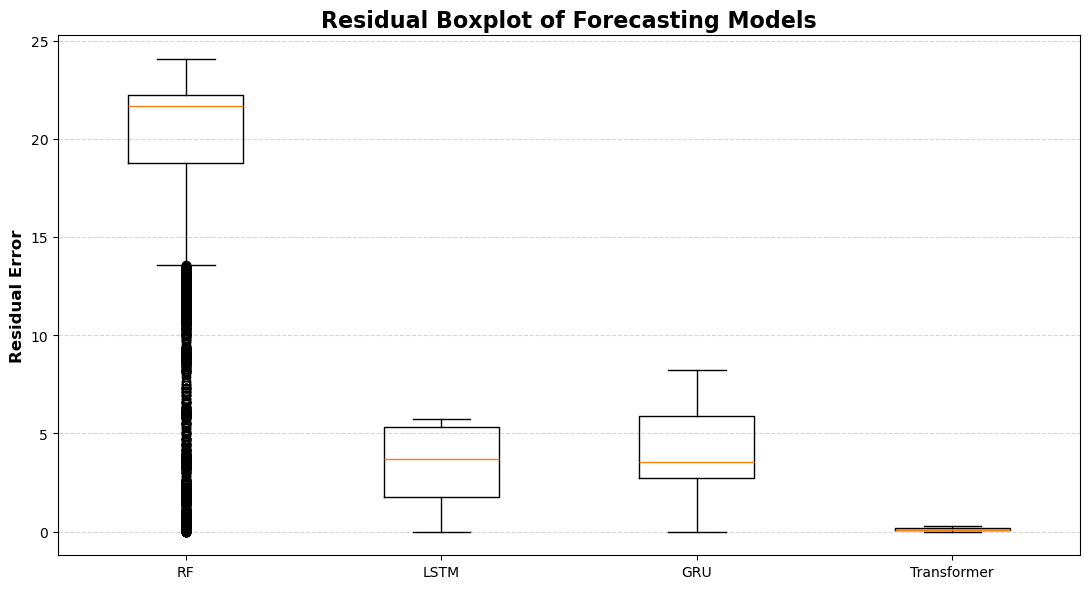

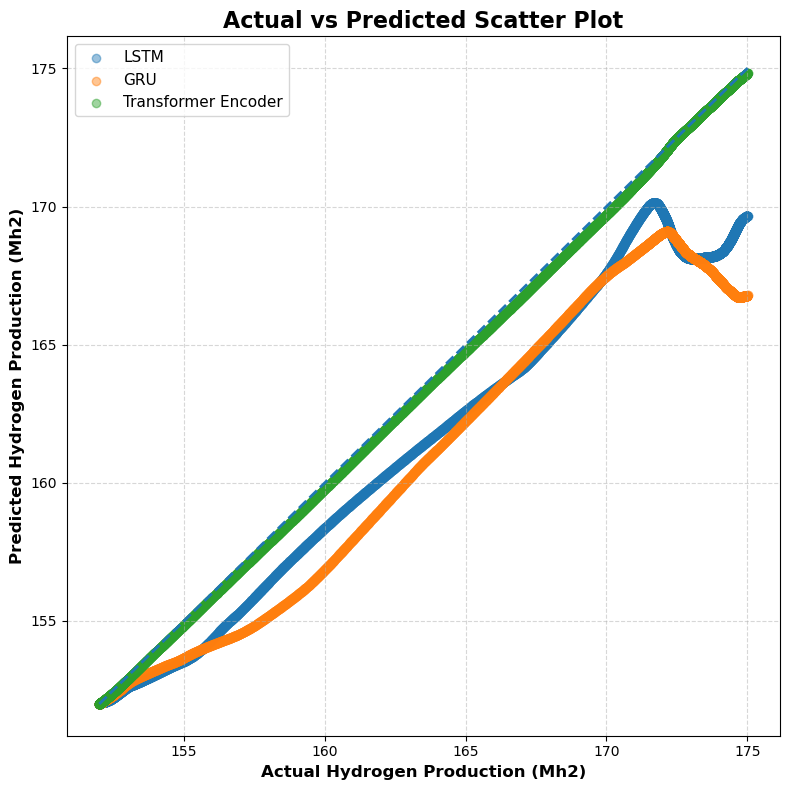


All updated conference paper figures saved in:
E:\Research WORK\7. ML green hydrogen microgrid\UPDATED_CONFERENCE_FIGURES

Updated model performance table:


,Model,MAE,RMSE,R2
0,Random Forest,18.4280,19.6399,-5.9634
1,LSTM,3.5077,3.9636,0.7161
2,GRU,4.0953,4.6565,0.6082
3,Transformer Encoder,0.1306,0.1532,0.9996


In [7]:
# ============================================================
# UPDATED CONFERENCE PAPER FIGURES
# RF + LSTM + GRU + Transformer Encoder
# Run this AFTER model training and prediction code
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ============================================================
# Save folder
# ============================================================
figure_folder = r"E:\Research WORK\7. ML green hydrogen microgrid\UPDATED_CONFERENCE_FIGURES"
os.makedirs(figure_folder, exist_ok=True)

# ============================================================
# Helper function
# ============================================================
def save_fig(filename):
    plt.tight_layout()
    plt.savefig(os.path.join(figure_folder, filename), dpi=600, bbox_inches="tight")
    plt.show()

# ============================================================
# Make RF and sequence data same length for comparison
# ============================================================
# RF test actual/prediction
rf_actual = np.array(y_test)
rf_prediction = np.array(rf_pred)

# Sequence model actual/prediction
actual_seq = np.array(mh2_test_actual)
lstm_prediction = np.array(lstm_pred)
gru_prediction = np.array(gru_pred)
transformer_prediction = np.array(transformer_pred)

# Residuals
rf_residual = rf_actual - rf_prediction
lstm_residual = actual_seq - lstm_prediction
gru_residual = actual_seq - gru_prediction
transformer_residual = actual_seq - transformer_prediction

# Absolute errors
rf_abs_error = np.abs(rf_residual)
lstm_abs_error = np.abs(lstm_residual)
gru_abs_error = np.abs(gru_residual)
transformer_abs_error = np.abs(transformer_residual)

# ============================================================
# Fig. 3: Feature Correlation Heatmap
# ============================================================
corr_data = df.select_dtypes(include=[np.number]).copy()
corr_matrix = corr_data.corr()

plt.figure(figsize=(14, 11))
plt.imshow(corr_matrix, aspect="auto")
plt.colorbar(label="Correlation Coefficient")
plt.xticks(
    ticks=np.arange(len(corr_matrix.columns)),
    labels=corr_matrix.columns,
    rotation=90,
    fontsize=8
)
plt.yticks(
    ticks=np.arange(len(corr_matrix.columns)),
    labels=corr_matrix.columns,
    fontsize=8
)
plt.title("Feature Correlation Heatmap", fontsize=16, fontweight="bold")
save_fig("Fig_3_Feature_Correlation_Heatmap.png")

# ============================================================
# Fig. 4: Random Forest Feature Importance
# ============================================================
rf_importance = pd.DataFrame({
    "Feature": features.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(rf_importance["Feature"], rf_importance["Importance"])
plt.xlabel("Feature Importance", fontsize=12, fontweight="bold")
plt.ylabel("Input Features", fontsize=12, fontweight="bold")
plt.title("Random Forest Feature Importance", fontsize=16, fontweight="bold")
plt.grid(axis="x", linestyle="--", alpha=0.5)
save_fig("Fig_4_Random_Forest_Feature_Importance.png")

# ============================================================
# Fig. 5: Actual Hydrogen Production Time-Series
# ============================================================
plt.figure(figsize=(13, 6))
plt.plot(target.values, linewidth=2.2)
plt.xlabel("Time Steps", fontsize=12, fontweight="bold")
plt.ylabel("Hydrogen Production (Mh2)", fontsize=12, fontweight="bold")
plt.title("Actual Hydrogen Production Time-Series", fontsize=16, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
save_fig("Fig_5_Actual_Hydrogen_Production_Time_Series.png")

# ============================================================
# Fig. 6: Actual vs Predicted Plot
# RF, LSTM, GRU, Transformer
# ============================================================
plt.figure(figsize=(14, 6))

plt.plot(actual_seq, label="Actual Mh2", linewidth=2.8)
plt.plot(lstm_prediction, label="LSTM", linewidth=2.0)
plt.plot(gru_prediction, label="GRU", linewidth=2.0)
plt.plot(transformer_prediction, label="Transformer Encoder", linewidth=2.0)

plt.xlabel("Time Steps", fontsize=12, fontweight="bold")
plt.ylabel("Hydrogen Production (Mh2)", fontsize=12, fontweight="bold")
plt.title("Actual vs Predicted Hydrogen Production for Sequence Models", fontsize=16, fontweight="bold")
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
save_fig("Fig_6_Actual_vs_Predicted_Sequence_Models.png")

# ============================================================
# Fig. 6b: RF Actual vs Predicted Separately
# Recommended because RF has different test alignment
# ============================================================
plt.figure(figsize=(14, 6))

plt.plot(rf_actual, label="Actual Mh2", linewidth=2.8)
plt.plot(rf_prediction, label="Random Forest", linewidth=2.0)

plt.xlabel("Time Steps", fontsize=12, fontweight="bold")
plt.ylabel("Hydrogen Production (Mh2)", fontsize=12, fontweight="bold")
plt.title("Actual vs Predicted Hydrogen Production for Random Forest", fontsize=16, fontweight="bold")
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
save_fig("Fig_6b_Actual_vs_Predicted_Random_Forest.png")

# ============================================================
# Fig. 7: Distribution of Hydrogen Prediction
# ============================================================
plt.figure(figsize=(13, 6))

plt.hist(actual_seq, bins=40, alpha=0.45, label="Actual Mh2")
plt.hist(lstm_prediction, bins=40, alpha=0.45, label="LSTM")
plt.hist(gru_prediction, bins=40, alpha=0.45, label="GRU")
plt.hist(transformer_prediction, bins=40, alpha=0.45, label="Transformer Encoder")

plt.xlabel("Hydrogen Production (Mh2)", fontsize=12, fontweight="bold")
plt.ylabel("Frequency", fontsize=12, fontweight="bold")
plt.title("Distribution of Actual and Predicted Hydrogen Production", fontsize=16, fontweight="bold")
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
save_fig("Fig_7_Prediction_Distribution_Comparison.png")

# ============================================================
# Fig. 8: Residual Comparison
# ============================================================
plt.figure(figsize=(14, 6))

plt.plot(lstm_residual, label="LSTM Residual", linewidth=1.8)
plt.plot(gru_residual, label="GRU Residual", linewidth=1.8)
plt.plot(transformer_residual, label="Transformer Encoder Residual", linewidth=1.8)
plt.axhline(0, linestyle="--", linewidth=1.5)

plt.xlabel("Time Steps", fontsize=12, fontweight="bold")
plt.ylabel("Residual Error", fontsize=12, fontweight="bold")
plt.title("Residual Comparison of Sequence Models", fontsize=16, fontweight="bold")
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
save_fig("Fig_8_Residual_Comparison_Sequence_Models.png")

# ============================================================
# Fig. 8b: RF Residual Separately
# ============================================================
plt.figure(figsize=(14, 6))

plt.plot(rf_residual, label="Random Forest Residual", linewidth=1.8)
plt.axhline(0, linestyle="--", linewidth=1.5)

plt.xlabel("Time Steps", fontsize=12, fontweight="bold")
plt.ylabel("Residual Error", fontsize=12, fontweight="bold")
plt.title("Residual Error of Random Forest", fontsize=16, fontweight="bold")
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
save_fig("Fig_8b_RF_Residual_Error.png")

# ============================================================
# Fig. 9: Error Histogram
# ============================================================
plt.figure(figsize=(13, 6))

plt.hist(lstm_residual, bins=40, alpha=0.45, label="LSTM")
plt.hist(gru_residual, bins=40, alpha=0.45, label="GRU")
plt.hist(transformer_residual, bins=40, alpha=0.45, label="Transformer Encoder")

plt.xlabel("Prediction Error", fontsize=12, fontweight="bold")
plt.ylabel("Frequency", fontsize=12, fontweight="bold")
plt.title("Error Histogram of Sequence Models", fontsize=16, fontweight="bold")
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
save_fig("Fig_9_Error_Histogram_Sequence_Models.png")

# ============================================================
# Fig. 9b: RF Error Histogram Separately
# ============================================================
plt.figure(figsize=(13, 6))

plt.hist(rf_residual, bins=40, alpha=0.65, label="Random Forest")

plt.xlabel("Prediction Error", fontsize=12, fontweight="bold")
plt.ylabel("Frequency", fontsize=12, fontweight="bold")
plt.title("Error Histogram of Random Forest", fontsize=16, fontweight="bold")
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
save_fig("Fig_9b_RF_Error_Histogram.png")

# ============================================================
# Fig. 10: Training vs Validation Loss Curves
# LSTM, GRU, Transformer
# ============================================================
plt.figure(figsize=(14, 6))

plt.plot(lstm_history.history["loss"], label="LSTM Training Loss", linewidth=2.0)
plt.plot(lstm_history.history["val_loss"], label="LSTM Validation Loss", linewidth=2.0)

plt.plot(gru_history.history["loss"], label="GRU Training Loss", linewidth=2.0)
plt.plot(gru_history.history["val_loss"], label="GRU Validation Loss", linewidth=2.0)

plt.plot(transformer_history.history["loss"], label="Transformer Training Loss", linewidth=2.0)
plt.plot(transformer_history.history["val_loss"], label="Transformer Validation Loss", linewidth=2.0)

plt.xlabel("Epoch", fontsize=12, fontweight="bold")
plt.ylabel("Loss (MSE)", fontsize=12, fontweight="bold")
plt.title("Training and Validation Loss Curves", fontsize=16, fontweight="bold")
plt.legend(fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
save_fig("Fig_10_Training_Validation_Loss_Curves.png")

# ============================================================
# Fig. 11: Model Performance Comparison Bar Chart
# MAE, RMSE, R2
# ============================================================
metric_table = pd.DataFrame({
    "Model": ["Random Forest", "LSTM", "GRU", "Transformer Encoder"],
    "MAE": [rf_mae, lstm_mae, gru_mae, transformer_mae],
    "RMSE": [rf_rmse, lstm_rmse, gru_rmse, transformer_rmse],
    "R2": [rf_r2, lstm_r2, gru_r2, transformer_r2]
})

x = np.arange(len(metric_table["Model"]))
width = 0.25

plt.figure(figsize=(13, 6))

plt.bar(x - width, metric_table["MAE"], width, label="MAE")
plt.bar(x, metric_table["RMSE"], width, label="RMSE")
plt.bar(x + width, metric_table["R2"], width, label="R²")

plt.xticks(x, metric_table["Model"], rotation=15)
plt.ylabel("Metric Value", fontsize=12, fontweight="bold")
plt.title("Model Performance Comparison", fontsize=16, fontweight="bold")
plt.legend(fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.5)
save_fig("Fig_11_Model_Performance_Comparison.png")

# ============================================================
# Fig. 11b: MAE and RMSE only
# Better because RF error is very high
# ============================================================
x = np.arange(len(metric_table["Model"]))
width = 0.35

plt.figure(figsize=(13, 6))

plt.bar(x - width/2, metric_table["MAE"], width, label="MAE")
plt.bar(x + width/2, metric_table["RMSE"], width, label="RMSE")

plt.xticks(x, metric_table["Model"], rotation=15)
plt.ylabel("Error Value", fontsize=12, fontweight="bold")
plt.title("MAE and RMSE Comparison of Forecasting Models", fontsize=16, fontweight="bold")
plt.legend(fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.5)
save_fig("Fig_11b_MAE_RMSE_Comparison.png")

# ============================================================
# Fig. 12: Residual Boxplot
# ============================================================
plt.figure(figsize=(11, 6))

plt.boxplot(
    [rf_residual, lstm_residual, gru_residual, transformer_residual],
    labels=["RF", "LSTM", "GRU", "Transformer"]
)

plt.ylabel("Residual Error", fontsize=12, fontweight="bold")
plt.title("Residual Boxplot of Forecasting Models", fontsize=16, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.5)
save_fig("Fig_12_Residual_Boxplot.png")

# ============================================================
# Fig. 13: Actual vs Predicted Scatter Plot
# ============================================================
plt.figure(figsize=(8, 8))

plt.scatter(actual_seq, lstm_prediction, alpha=0.45, label="LSTM")
plt.scatter(actual_seq, gru_prediction, alpha=0.45, label="GRU")
plt.scatter(actual_seq, transformer_prediction, alpha=0.45, label="Transformer Encoder")

min_val = min(actual_seq.min(), lstm_prediction.min(), gru_prediction.min(), transformer_prediction.min())
max_val = max(actual_seq.max(), lstm_prediction.max(), gru_prediction.max(), transformer_prediction.max())

plt.plot([min_val, max_val], [min_val, max_val], linestyle="--", linewidth=2)

plt.xlabel("Actual Hydrogen Production (Mh2)", fontsize=12, fontweight="bold")
plt.ylabel("Predicted Hydrogen Production (Mh2)", fontsize=12, fontweight="bold")
plt.title("Actual vs Predicted Scatter Plot", fontsize=16, fontweight="bold")
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
save_fig("Fig_13_Actual_vs_Predicted_Scatter.png")

# ============================================================
# Save metric table
# ============================================================
metric_table_rounded = metric_table.round(4)

metric_table_rounded.to_csv(
    os.path.join(figure_folder, "Updated_Model_Performance_Table.csv"),
    index=False
)

metric_table_rounded.to_latex(
    os.path.join(figure_folder, "Updated_Model_Performance_Table.tex"),
    index=False
)

print("\nAll updated conference paper figures saved in:")
print(figure_folder)

print("\nUpdated model performance table:")
display(metric_table_rounded)

                 Model  MAE Reduction vs RF (%)  RMSE Reduction vs RF (%)
0        Random Forest                     0.00                      0.00
1                 LSTM                    80.97                     79.82
2                  GRU                    77.78                     76.29
3  Transformer Encoder                    99.29                     99.22


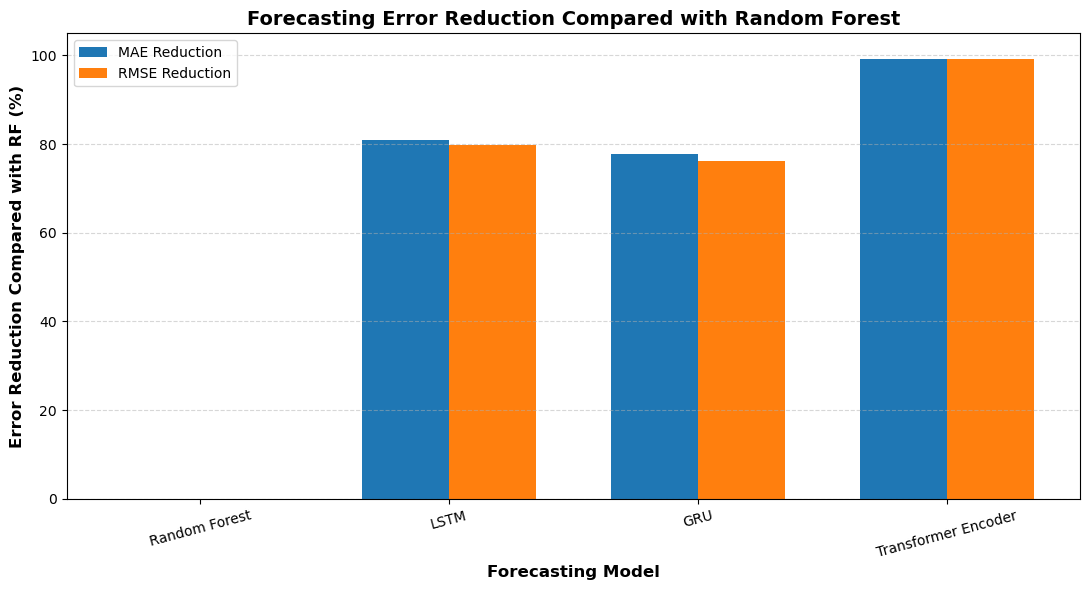

In [7]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Save folder
save_folder = r"E:\Research WORK\7. ML green hydrogen microgrid\SYSTEM_LEVEL_ANALYSIS"
os.makedirs(save_folder, exist_ok=True)

# Table III values
models = ["Random Forest", "LSTM", "GRU", "Transformer Encoder"]

mae = np.array([18.4280, 3.5077, 4.0953, 0.1306])
rmse = np.array([19.6399, 3.9636, 4.6565, 0.1532])

# Error reduction compared with Random Forest
mae_reduction = ((mae[0] - mae) / mae[0]) * 100
rmse_reduction = ((rmse[0] - rmse) / rmse[0]) * 100

# Create table
reduction_table = pd.DataFrame({
    "Model": models,
    "MAE Reduction vs RF (%)": mae_reduction,
    "RMSE Reduction vs RF (%)": rmse_reduction
})

reduction_table = reduction_table.round(2)

print(reduction_table)

# Plot
x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(x - width/2, mae_reduction, width, label="MAE Reduction")
plt.bar(x + width/2, rmse_reduction, width, label="RMSE Reduction")

plt.xticks(x, models, rotation=15)
plt.ylabel("Error Reduction Compared with RF (%)", fontsize=12, fontweight="bold")
plt.xlabel("Forecasting Model", fontsize=12, fontweight="bold")
plt.title("Forecasting Error Reduction Compared with Random Forest", fontsize=14, fontweight="bold")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.ylim(0, 105)

plt.tight_layout()
plt.savefig(
    os.path.join(save_folder, "Fig_Error_Reduction_vs_RF.png"),
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# Save table
reduction_table.to_csv(
    os.path.join(save_folder, "Error_Reduction_vs_RF_Table.csv"),
    index=False
)